# STAT0004 · R 复习笔记本

中英复习笔记 + 可运行练习。

右上角内核：**R (STAT0004)**。选中代码单元后按 **Shift + Enter** 运行。

说明中的代码块用于阅读；标为“动手练习”的代码单元可直接运行，不依赖课程 CSV。完整笔记中的 `qanda` 示例需要另行导入课程数据。

In [1]:
cat("R 环境已就绪 / R is ready!\n")
R.version.string
getwd()

R 环境已就绪 / R is ready!


[1] "R version 4.5.1 (2025-06-13)"

[1] "/Users/zhouziyang/Documents/ChatGPT/Stats0004"

# STAT0004 第 1–5 周：中英结合复习笔记

这份笔记按学习逻辑重新组织，结合 Chapter 1–5、课堂 demo 和已提供的练习解答。代码优先使用自己创建的小数据，方便你直接运行；涉及 `qanda` 的部分需要先导入课程 CSV。原材料中的错误已在对应知识点修正。

## 先看全貌：这五周到底在学什么？

**用 R 做数据分析的基本过程：**

`输入或导入数据 → 检查结构与质量 → 选取需要的数据 → 计算统计量 → 画图 → 保存结果`

| 周次 | 核心问题 | 关键词 |
|---|---|---|
| Week 1 | 怎样让 R 计算并记住结果？ | calculation, assignment, script |
| Week 2 | 数据怎么存放？怎么选取其中一部分？ | vector, indexing, matrix, class |
| Week 3 | 怎样读取和初步检查真实数据？ | import, data frame, summary, correlation |
| Week 4 | 什么数据应该用什么图？ | bar chart, histogram, boxplot, scatterplot |
| Week 5 | 怎样让图清楚、易读？ | lines, legend, annotation, axis, points |

---

## Week 1：R 基础 / R basics

### 1. R、RStudio、Console、Script 有什么区别？

- **R**：实际执行计算的编程语言。
- **RStudio**：帮助你写、运行、管理 R 代码的软件，也叫 IDE。
- **Console（控制台）**：立即运行命令，适合临时尝试。
- **Script（脚本）**：保存代码的 `.R` 文件，方便修改和重复运行。
- **Environment（环境）**：查看当前会话中创建的对象。
- **Plots / Help**：查看图形和函数帮助。

**理解：** Console 像临时计算纸；Script 像保留下来的计算步骤。

```r
3 + 5
# 8

# 这一行是注释 comment，不会执行。
```

输出中的 `[1]` 表示这一行显示的第一个元素在结果中的位置，不是答案的一部分。

### 2. 运算顺序 / Order of operations

**括号 → 幂 → 乘除 → 加减。** 乘除同级，加减同级，同级通常从左到右算。

```r
10 - 2 * 3       # 4
(10 - 2) * 3     # 24
2^4             # 16
8 / 2 * 4       # 16
8 / (2 * 4)     # 1
```

注意：幂的连续运算是从右结合，如 `2^3^2` 等于 `2^(3^2)`。遇到不确定的表达式，主动加括号。

### 3. 常用数学函数 / Mathematical functions

| R 写法 | 数学含义 | 例子 |
|---|---|---|
| `pi` | 圆周率 π | `pi / 2` |
| `sqrt(x)` | 平方根 √x | `sqrt(25)` → 5 |
| `exp(x)` | e 的 x 次方 | `exp(0)` → 1 |
| `log(x)` | 自然对数 ln(x)，底数 e | `log(exp(2))` → 2 |
| `log10(x)` | 以 10 为底的对数 | `log10(100)` → 2 |
| `log(x, base = 2)` | 指定底数的对数 | `log(8, base = 2)` → 3 |
| `abs(x)` | 绝对值 | `abs(-5)` → 5 |
| `floor(x)` | 向下取整 | `floor(3.9)` → 3 |
| `ceiling(x)` | 向上取整 | `ceiling(3.1)` → 4 |
| `round(x, 1)` | 保留一位小数 | `round(3.14159, 1)` → 3.1 |

**三角函数用 radians（弧度）作为输入。**

```r
cos(pi)         # -1
sin(pi / 2)     # 1
```

角度换算：`弧度 = 角度 × pi / 180`；`角度 = 弧度 × 180 / pi`。

原 Exercise 1.2：`90 / (pi / 4)` 约为 **114.5916**，这个数等于 **2 弧度对应的角度数**；它本身不是数值 2。

### 4. 赋值 / Assignment

```r
radius <- 5
area <- pi * radius^2
area
```

`<-` 的意思是：**计算右边，然后把结果存到左边的名字里。**

```r
a <- 2
a <- a + 1
a               # 3
```

`a <- a + 1` 是更新对象，不是数学方程。R 区分大小写：`Height` 和 `height` 是不同名字。

### 5. 科学计数法 / Scientific notation

`1.2e+06 = 1.2 × 10^6 = 1,200,000`

`1.2e-06 = 1.2 × 10^-6 = 0.0000012`

```r
2^40
# 1099511627776，显示时可能采用科学计数法
```

### 6. 整除与余数 / Integer division and remainder

```r
29 / 6          # 普通除法，约 4.833333
29 %/% 6        # 整除商：4
29 %% 6         # 余数：5
```

对本课程中的正整数：**被除数 = 整除商 × 除数 + 余数。**

```r
666 - floor(666 / 17) * 17   # 3
666 %% 17                    # 3
```

注意 `floor(-2.7)` 是 -3，不是 -2；floor 是向下取整，不是简单删掉小数。

### 7. 帮助、报错与输出 / Help, errors and output

```r
?mean
help(mean)
```

帮助页重点看 **Usage（用法）/ Arguments（参数）/ Value（返回什么）/ Examples（例子）**。

常见报错：`object 'width' not found` 表示找不到这个对象。检查是否创建过、是否拼错或大小写不一致。

```r
height <- 10
width <- 4
height * width              # 40
```

执行保存的脚本：

```r
source("my_script.R")
```

`source()` 默认不会像交互式 Console 那样自动显示每个裸表达式的结果。想稳定输出，用 `print()` 或 `cat()`。

```r
print(area)                         # 显示对象，适合表格等结构化结果
cat("Area =", area, "\n")           # 组合文字和数值；\n 表示换行
```

---

### Week 1 动手练习 / Run it yourself
先预测结果，再运行下面的代码。

In [2]:
radius <- 5
area <- pi * radius^2
cat("Area =", area, "\n")
666 %% 17

Area = 78.53982 


[1] 3

## Week 2：数据怎么存、怎么选 / Data structures and indexing

### 1. 向量 / Vector

本章常用的 **atomic vector（原子向量）** 是有顺序、元素具有共同类型的一串值。

```r
x <- c(2, 4, 6, 8, 10)
length(x)                   # 5
```

`c()` = combine，把元素连接起来。

```r
1:5                         # 1 2 3 4 5
seq(from = 2, to = 10, by = 2)
# 2 4 6 8 10
```

`:` 的步长为 1 或 -1，起点不一定是整数，例如 `1.5:3.5`。需要自定义步长时用 `seq()`。

### 2. 索引 / Indexing：最重要的基础

**R 的位置从 1 开始。** `[]` 是选择元素；括号里可以放位置，也可以放逻辑条件。

| 写法 | 含义 | 对 x 的结果 |
|---|---|---|
| `x[3]` | 第 3 个元素 | 6 |
| `x[2:4]` | 第 2 到第 4 个 | 4, 6, 8 |
| `x[c(1, 5)]` | 第 1 和第 5 个 | 2, 10 |
| `x[-3]` | 去掉第 3 个 | 2, 4, 8, 10 |
| `x[x > 5]` | 保留值大于 5 的 | 6, 8, 10 |

**位置和数值不同：** `x[3]` 不是“找值为 3 的元素”。

把条件筛选拆成两步：

```r
x > 5
# FALSE FALSE TRUE TRUE TRUE

x[x > 5]
# 6 8 10
```

条件给每个位置贴上 TRUE/FALSE 标签；TRUE 的位置被保留。

### 3. 比较与逻辑 / Comparison and logic

| 运算符 | 意思 |
|---|---|
| `==` | 等于 |
| `!=` | 不等于 |
| `>` / `<` | 大于 / 小于 |
| `>=` / `<=` | 大于等于 / 小于等于 |
| `&` | AND，同时满足 |
| `\|` | OR，至少满足一个 |
| `!` | NOT，取反 |

```r
x[x > 3 & x < 9]             # 4 6 8
x[x == 2 | x == 10]          # 2 10
(1:20)[(1:20) %% 3 == 0]     # 3 6 9 12 15 18
```

**`<-` 存值，`==` 比较。** 对向量逐元素筛选用 `&`、`|`。

### 4. 逐元素计算 / Element-wise operations

```r
x + 1                       # 每个元素加 1
x^2                         # 每个元素平方
x * x                       # 对应位置相乘，等于 x^2
```

运算长度不同时，R 可能重复使用短向量的元素，称为 **recycling（循环补齐）**。

```r
c(1, 2, 3, 4) + c(10, 20)
# 11 22 13 24
```

不小心循环补齐可能得到“能运行但不是你想要”的结果；做成对计算前检查长度。

### 5. 统计数据分类 ≠ R 存储类型

**统计类型问：数值代表什么？**

| 类型 | 英文 | 关键特征 | 例子 |
|---|---|---|---|
| 连续型 | continuous | 理论上可取某个区间内任意值 | 身高、手掌跨度 |
| 离散型 | discrete | 取有限或可数多个可能值 | 兄弟姐妹人数 |
| 有序分类 | ordinal | 类别有明确顺序 | Low < Medium < High |
| 无序分类 | nominal | 类别没有自然顺序 | 发色 |

连续测量被四舍五入成整数，不会因此变成“计数”；数字 0/1 也可能只是类别编码。

**R 类型问：计算机如何保存和处理它？**

```r
class(2)                    # "numeric"，通常底层存储为 double
class(2L)                   # "integer"
class(TRUE)                 # "logical"
class("2")                  # "character"
class(1i)                   # "complex"
```

`"2"` 是文字，`2` 是数值。

```r
c(1, 2, "3")
# "1" "2" "3"：共同转换成 character，称为 coercion

as.numeric("3")             # 3
as.integer(2.9)             # 2，截去小数，不是四舍五入
integer(2)                  # 0 0：两个整数零，不是整数值 2
```

### 6. 因子 / Factor：表达类别

```r
confidence <- factor(
  c("Low", "High", "Medium", "Low"),
  levels = c("Low", "Medium", "High"),
  ordered = TRUE
)
table(confidence)
```

`levels` 指定类别及排列顺序；`ordered = TRUE` 额外表达类别有顺序。仅仅安排 levels 不等于创建 ordered factor。

**注意：** 指定 levels 之外的值会变成 `NA`。也不要直接用 `as.numeric(factor_object)` 恢复标签中的数字，它通常返回内部类别编号。

### 7. 矩阵 / Matrix

```r
M <- matrix(1:9, nrow = 3)
M
#      [,1] [,2] [,3]
# [1,]    1    4    7
# [2,]    2    5    8
# [3,]    3    6    9
```

默认 **按列填充 / fill by column**。按行填充要加 `byrow = TRUE`。

```r
M[2, 3]                     # 8；[行 row, 列 column]
M[2, ]                      # 第 2 行：2 5 8
M[, 3]                      # 第 3 列：7 8 9
M[1:2, 2:3]                 # 选取一个子矩阵
nrow(M)                     # 3
ncol(M)                     # 3
dim(M)                      # 3 3
```

**乘法特别容易混淆：**

```r
M * M                       # 对应元素相乘
M^2                         # 每个元素平方
M %*% M                     # 矩阵乘法：左行 × 右列再求和
t(M)                        # 转置 transpose
```

矩阵乘法要求：**左矩阵列数 = 右矩阵行数**。

`solve(A)`：求可逆方阵的逆。`solve(A, b)`：直接求解线性方程组 `A x = b`。

### 8. 数组 / Array

矩阵是二维数组；array 可以有更多维。

```r
Burr <- array(1:24, dim = c(2, 3, 4))
dim(Burr)                   # 2 3 4
Burr[1, 2, 3]               # 15
Burr[, , 2]                 # 第 2 个二维切片
```

可以把它想成 4 页，每页是一张 2 行 3 列的表。填充时第一个索引变化最快。

本课程的 `%*%` 主要用于向量和矩阵；不要把它理解成任意高维数组都能直接相乘。

---

### Week 2 动手练习 / Run it yourself
先预测结果，再运行下面的代码。

In [3]:
x <- c(2, 4, 6, 8, 10)
x > 5
x[x > 5]
M <- matrix(1:9, nrow = 3)
M
M * M
M %*% M

[1] FALSE FALSE  TRUE  TRUE  TRUE

[1]  6  8 10

1,4,7
2,5,8
3,6,9


1,16,49
4,25,64
9,36,81


30,66,102
36,81,126
42,96,150


## Week 3：导入与探索 / Importing and exploring data

### 1. 工作目录 / Working directory

```r
getwd()                     # 当前默认读写文件的位置
list.files()                # 这个位置有哪些文件
# setwd("你的文件夹路径")
```

`read.csv("data.csv")` 表示从当前 working directory 找文件，不是自动从脚本所在位置找。

使用 **RStudio Project** 可以让每次打开项目时自动使用项目文件夹作为工作目录。

### 2. 导入文件 / Import files

```r
qanda <- read.csv(
  "selective_affinities.csv",
  colClasses = c(Hair = "factor", Birth = "factor", Hand = "factor")
)
```

- `read.csv()`：默认首行是列名，默认逗号分隔。
- `colClasses`：指定某些列导入后的类型；这里三列作为分类变量。
- 列名必须与文件实际列名匹配。

```r
text_data <- read.table("selective_affinities2.txt", header = TRUE)
```

`read.table()` 默认 `header = FALSE`，默认以空白分隔。文件若用其他分隔符，要相应设置 `sep`。`.txt` 后缀本身不能告诉你文件怎样分隔。

### 3. 数据框 / Data frame

**通常一行是一个 observation（观测对象），一列是一个 variable（变量）。**

矩阵通常使用共同的元素类型；data frame 的不同列可以有不同类型。

```r
students <- data.frame(
  Height = c(160, 170, 180, 175),
  Siblings = c(0, 1, 2, 1),
  Hair = factor(c("Black", "Brown", "Black", "Brown"))
)

head(students)               # 前几行，默认最多 6 行
tail(students)               # 后几行
str(students)                # 结构、列类型和内容预览
names(students)              # 列名
dim(students)                # 行数、列数
```

导入真实数据后，先看 `str()`、`head()` 和 `summary()`，再做分析。

```r
students$Height
students[, "Height"]
students[, 1]
# 这里三种写法选择同一列；按名字更不容易受列顺序变化影响

students[students$Siblings >= 1, c("Height", "Hair")]
```

`$` 后的名字区分大小写。不存在的列，如 `students$height`，通常返回 `NULL`。

### 4. 常用统计量 / Summary statistics

| 函数 | 含义 | 理解 |
|---|---|---|
| `mean(x)` | 均值 mean | 总和 ÷ 个数，容易受极端值影响 |
| `median(x)` | 中位数 median | 排序后的中心位置 |
| `var(x)` | 样本方差 sample variance | 平方偏差和 ÷ (n−1) |
| `sd(x)` | 样本标准差 sample SD | 样本方差的平方根，单位与原数据一致 |
| `min(x)` / `max(x)` | 最小 / 最大值 | 数据的两个端点 |
| `range(x)` | 最小值和最大值 | 返回两个端点，不是直接返回极差 |
| `summary(x)` | 综合摘要 | 结果取决于对象类型 |
| `table(x)` | 频数表 frequency table | 每个值或类别出现多少次 |

数值向量的 `summary()` 通常显示：**Min、1st Qu.、Median、Mean、3rd Qu.、Max**；若有缺失值还会报告数量。

**三个易错点：**

- 极差 range 的数值是 `max(x) - min(x)`，也可以写 `diff(range(x))`。
- `mode(x)` 不是统计学的众数。求众数要找 `table(x)` 中频数最大的类别。
- 因子的 `summary()` 可以显示各类别计数，所以不能说 summary 对所有分类数据都没用。

```r
z <- c(1, 2, 2, 3, 3)
tab <- table(z)
names(tab)[tab == max(tab)]
# "2" "3"，保留并列众数
```

### 5. 缺失值 / Missing values

`NA` 表示缺失，不是零。

```r
x <- c(160, 170, NA, 180)
mean(x)                     # NA
mean(x, na.rm = TRUE)       # 170
is.na(x)                    # FALSE FALSE TRUE FALSE
sum(is.na(x))               # 1
```

对 `sd()`、`median()`、`min()`、`max()` 等，也可使用 `na.rm = TRUE`。`table()` 默认不计 NA；想看缺失数用 `table(x, useNA = "ifany")`。

忽略缺失值只是选择可用数据进行计算，并没有解决“为什么缺失”的问题。

### 6. 相关 / Correlation

**Univariate = 看一个变量；Bivariate = 同时看两个变量。**

```r
cor(qanda$Handspan, qanda$Height, use = "complete.obs")
```

默认 Pearson correlation 衡量 **linear association（线性关联）**：

- r 接近 1：较强正线性关联。
- r 接近 −1：较强负线性关联。
- r 接近 0：线性关联较弱，但仍可能有非线性关联。
- 相关不代表因果 / Correlation does not imply causation。

相关系数不是斜率，也不是“有多少百分比的数据符合关系”。

```r
cor.test(qanda$Siblings, qanda$Shoes)
```

`cor()` 给相关系数；默认的 `cor.test()` 还会检验总体相关是否为 0，给出 p-value 等结果。显著性与关系强弱不同；不显著也不等于证明没有关系。

计算 Pearson r 时，若协方差和两个方差统一采用 n 或 n−1 作分母，因子会约掉，r 不变。

### 7. 保存 / Saving

```r
save(qanda, file = "qanda.RData")
load("qanda.RData")

write.csv(qanda, "qanda_export.csv", row.names = FALSE)
```

- `.R`：代码。
- `.RData`：R 对象，保留其结构和类等信息。
- `.csv`：可交换的文本表格，重新导入后可能需要重新指定类型。

---

### Week 3 动手练习 / Run it yourself
先预测结果，再运行下面的代码。

In [4]:
students <- data.frame(Height = c(160, 170, 180, 175),
                       Siblings = c(0, 1, 2, 1),
                       Hair = factor(c("Black", "Brown", "Black", "Brown")))
str(students)
summary(students)
table(students$Hair)
mean(students$Height)
sd(students$Height)

'data.frame':	4 obs. of  3 variables:
 $ Height  : num  160 170 180 175
 $ Siblings: num  0 1 2 1
 $ Hair    : Factor w/ 2 levels "Black","Brown": 1 2 1 2


     Height         Siblings       Hair  
 Min.   :160.0   Min.   :0.00   Black:2  
 1st Qu.:167.5   1st Qu.:0.75   Brown:2  
 Median :172.5   Median :1.00            
 Mean   :171.2   Mean   :1.00            
 3rd Qu.:176.2   3rd Qu.:1.25            
 Max.   :180.0   Max.   :2.00            


Black Brown 
    2     2 

[1] 171.25

[1] 8.539126

## Week 4：怎样选图 / Choosing a plot

### 1. 先问：变量是什么类型？看几个变量？

| 想回答的问题 | 推荐图 | 原因 |
|---|---|---|
| 每个类别有多少人？ | bar chart 条形图 | 比较类别频数 |
| 一个数值变量怎么分布？ | histogram 直方图 | 看形状、偏态、峰和尾部 |
| 中心、离散程度、潜在异常值？ | boxplot 箱线图 | 简洁展示分布特征 |
| 各组数值分布是否不同？ | grouped boxplot 分组箱线图 | 比较不同组 |
| 每个实际观测值在哪？ | stripchart 点图 | 展示个体观测，可堆叠或抖动 |
| 两个数值变量有没有关联？ | scatterplot 散点图 | 看方向、形状和异常值 |
| 随时间或其他有序变量怎么变？ | line plot 折线图 | 按有意义的顺序连接 |

### 2. 条形图 / Bar chart

```r
siblings <- c(0, 1, 1, 2, 0, 3, 1, 2)
counts <- table(factor(siblings, levels = 0:3))

barplot(counts,
        main = "Number of siblings",
        xlab = "Siblings", ylab = "Number of students",
        col = "steelblue")
```

`table()` 先数，`barplot()` 再画。注意 `barplot(siblings)` 会把每个观测值当作柱高，不是自动统计频数。

指定 factor levels 可以显示零频数类别，但不要把真实值漏在 levels 外。

### 3. plot() 为什么同一个函数能画不同图？

```r
plot(siblings)               # 横轴是观测位置 index，纵轴是对应数值
plot(table(siblings))        # 对 table 对象，通常画竖线表示频数
```

`plot()` 是 **generic function（泛型函数）**：根据输入对象的 class 选择相应的绘图方法。

### 4. 直方图 / Histogram

```r
height <- c(158, 162, 165, 168, 170, 171, 175, 181)

hist(height,
     main = "Height distribution",
     xlab = "Height (cm)", col = "lightblue")

hist(height, breaks = seq(150, 190, by = 5))
```

**Breaks（组界）**把数轴切成 bins（区间）。组数太少会隐藏细节，太多可能让随机波动显得很重要。

- `breaks = 12`：建议大约 12 组，实际组数不保证恰好是 12。
- `breaks = c(...)`：明确指定组界；必须覆盖要绘制的全部数据。
- `xlim`：控制显示范围，不会替你重新定义组界或筛选数据。

**Frequency vs density：**

```r
hist(height, freq = TRUE)    # 等宽组时可用柱高比较频数
hist(height, freq = FALSE)   # 密度图：总面积为 1
```

**Density = 该组频数 ÷ (总观测数 × 组宽)。**

密度图的柱高不是比例；柱子的面积才是该区间的观测比例。组宽不等时，用面积比较尤其重要。

条形图表示类别，直方图表示数值区间；不能只靠“柱子之间有没有空隙”辨别。

### 5. 箱线图 / Boxplot

```r
boxplot(height, ylab = "Height (cm)")
boxplot(Height ~ Hair, data = students,
        xlab = "Hair colour", ylab = "Height (cm)")
```

公式 `数值变量 ~ 分组变量` 表示按右边的组比较左边的数值。

- 箱内横线：median，中位数。
- 箱子边缘：lower / upper hinges，位置接近 Q1、Q3；小样本时可能与 `quantile()` 默认四分位数不同。
- 须 whiskers：默认延伸到距离相应 hinge 不超过 1.5 倍箱长的最远观测值。
- 须外点：被这条规则标记的潜在异常值，不一定是错误数据。

**须不一定等于最小值和最大值。** 比较组间箱线图时，也要看每组样本量，不能只看箱子。

### 6. 点图 / Stripchart

```r
stripchart(siblings, method = "stack", pch = 16)
stripchart(height, method = "jitter", pch = 16)
```

- `stack`：重复值堆叠起来，适合取值较少、重复较多的数据。
- `jitter`：加入小幅位置扰动，减少重叠；不要把抖动误认成原数据值的改变。

### 7. 散点图 / Scatterplot

```r
plot(qanda$Handspan, qanda$Height,
     main = "Handspan and height",
     xlab = "Handspan (cm)", ylab = "Height (cm)",
     pch = 16, col = "navy")
```

看四件事：**方向 direction、形状 form、强弱 strength、异常点 outliers**。

### 8. 多图与保存 / Layout and export

```r
par(mfrow = c(1, 2))         # 1 行 2 列，按行放图
hist(height)
boxplot(height)
par(mfrow = c(1, 1))         # 恢复
```

保存时，可以先打开文件设备、画图、最后关闭：

```r
pdf("height_plot.pdf", width = 7, height = 5)
hist(height, main = "Height distribution", xlab = "Height (cm)")
dev.off()

png("height_plot.png", width = 30, height = 18.5,
    units = "cm", res = 300)
hist(height, main = "Height distribution", xlab = "Height (cm)")
dev.off()
```

PDF 的 width、height 通常以 inches（英寸）计；PNG 可指定单位，`res = 300` 表示每英寸 300 像素。`dev.off()` 关闭设备，完成文件写入。

课程中的 `dev.copy()` 是另一种方法：复制当前图到文件设备，然后 `dev.off()`。

---

### Week 4 动手练习 / Run it yourself
先预测结果，再运行下面的代码。

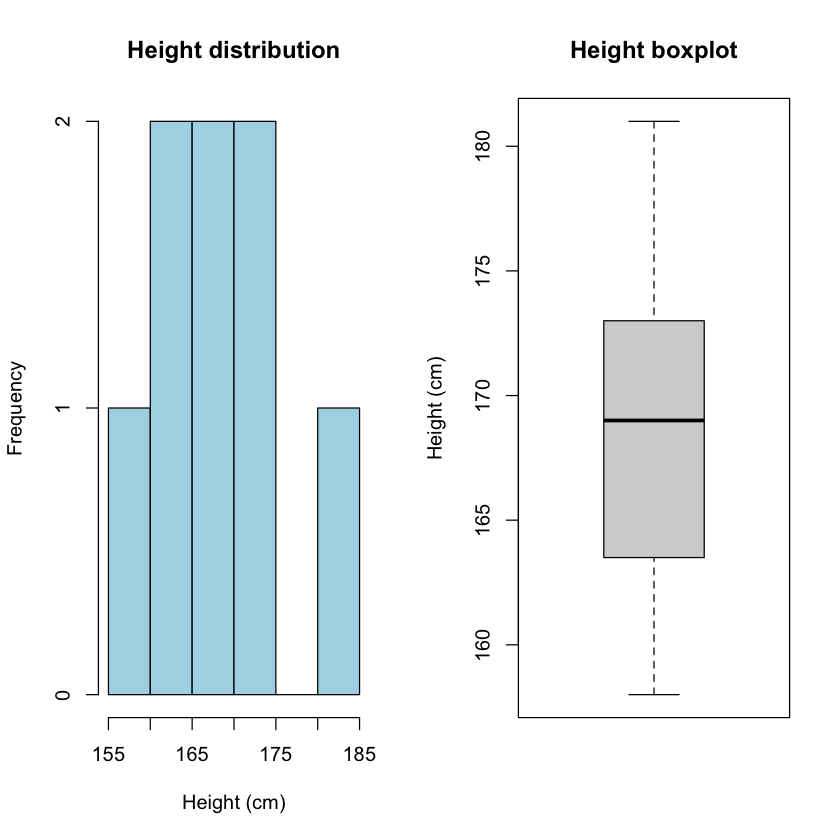

In [5]:
heights <- c(158, 162, 165, 168, 170, 171, 175, 181)
par(mfrow = c(1, 2))
hist(heights, main = "Height distribution", xlab = "Height (cm)", col = "lightblue")
boxplot(heights, main = "Height boxplot", ylab = "Height (cm)")
par(mfrow = c(1, 1))

## Week 5：让图更清楚 / Plot features

### 1. 新建一张图，还是在原图上添加？

| 函数 | 作用 |
|---|---|
| `plot()`、`hist()`、`boxplot()` 等 | 通常新建图；多面板布局下进入下一个面板 |
| `points()` | 给当前图加点 |
| `lines()` | 按提供的顺序连接点 |
| `abline()` | 加直线、水平线或垂直线 |
| `legend()` | 加图例 |
| `text()` | 在坐标处加文字 |
| `axis()` | 加坐标轴 |

**顺序非常重要：先创建图，再添加元素。** 再次调用 `plot()` 通常就开始另一张图，前面的添加不会自动带过去。

### 2. 常用外观参数 / Appearance arguments

| 参数 | 控制什么 | 示例 |
|---|---|---|
| `main` | 标题 | `main = "Height"` |
| `xlab`, `ylab` | 轴标题 | `xlab = "Height (cm)"` |
| `col` | 颜色 | `col = "red"` |
| `pch` | 点形状 | 16 实心圆，17 实心三角，3 加号 |
| `cex` | 点或文字的大小倍数，依函数而定 | `cex = 0.8` |
| `cex.main` | 标题字号倍数 | `cex.main = 1.5` |
| `lwd` | 线宽 | `lwd = 2` |
| `lty` | 线型 | 1 实线，2 虚线，3 点线 |
| `xlim`, `ylim` | 显示范围 | `ylim = c(0, 100)` |

### 3. lines() 与 abline() 的区别

```r
month <- 1:4
price <- c(2300, 2500, 2400, 2700)

plot(month, price, type = "p", ylim = c(2000, 3000))
lines(month, price, col = "blue")
abline(h = mean(price), col = "red", lty = 2)
```

- `lines(x, y)`：按给定顺序把数据点连接起来，不会自动按 x 排序。
- `abline(h = k)`：水平线 y = k。
- `abline(v = k)`：垂直线 x = k。
- `abline(a = a0, b = b0)`：直线 y = a0 + b0 x。

不要把没有自然顺序的学生观测随便连成折线。

### 4. 图例与文字 / Legend and annotation

```r
legend("topleft",
       legend = c("Monthly price", "Mean price"),
       col = c("blue", "red"), lty = c(1, 2),
       bty = "n")

text(x = 2, y = mean(price), labels = "Mean price", pos = 3)
```

图例的颜色、线型和点形状必须与实际图一致。

- `bty = "n"`：无边框。
- `bty = "o"`：有边框；不要写 `bty = 1`。
- `pos = 1, 2, 3, 4`：文字分别位于指定坐标的下、左、上、右。

### 5. 自定义坐标轴 / Custom axes

```r
plot(month, price, type = "l", xaxt = "n",
     xlab = "Month", ylab = "Price")
axis(side = 1, at = 1:4, labels = c("Jan", "Feb", "Mar", "Apr"))
```

`xaxt = "n"` 关闭默认 x 轴，再用 `axis()` 添加。

轴编号：**1 下、2 左、3 上、4 右**。`at` 是放刻度的位置，`labels` 是显示的文字。

### 6. 分组均值与加点 / Group means and points

```r
boxplot(Height ~ Hair, data = students)

group_means <- tapply(students$Height, students$Hair,
                      mean, na.rm = TRUE)
points(seq_along(group_means), group_means,
       pch = 17, col = "red")
```

`tapply(数值, 分组, 函数)`：按组对数值使用函数。箱内线仍是中位数；新加三角形表示均值。

`varwidth = TRUE` 的箱线图宽度与组样本量的平方根成比例，不是与人数直接成比例。

### 7. 按组着色 / Colour by group

```r
g <- factor(c("A", "B", "A", "B"), levels = c("A", "B"))
colours <- c("orange", "blue")
symbols <- c(16, 17)

plot(1:4, c(3, 6, 4, 8), col = colours[g], pch = symbols[g])
legend("topleft", legend = levels(g), col = colours,
       pch = symbols, bty = "n")
```

这里 factor 的内部编号让各组对应到颜色与符号。颜色向量顺序必须与 levels 顺序一致。

### 8. 月份排序 / Ordering months

```r
birth <- c("March", "January", "March", "December")
birth_counts <- table(factor(birth, levels = month.name))
barplot(birth_counts, names.arg = month.abb)
```

`month.name` 是 January 到 December；`month.abb` 是 Jan 到 Dec。原始文字必须匹配，缩写、数字月份或拼写差异需要先处理。

### 9. Chapter 5 的数据整理 / String manipulation and reshaping

这一部分虽然没有在 demo 中完整展示，但做 cocoa 练习要会。

```r
date_text <- c("Jan-12", "Feb-12", "Jan-13", "Feb-13")
Mths <- substr(date_text, start = 1, stop = 3)
Yrs <- paste("20", substr(date_text, start = 5, stop = 6), sep = "")
```

- `substr(x, start, stop)`：按字符位置截取，起止位置都包括。
- `paste()`：拼接文字；默认用空格分隔。
- `sep = ""`：不插入空格，否则可能得到 `"20 12"`。
- `paste0()`：等价于这种不加分隔符的拼接。

```r
cocoa <- data.frame(
  Yrs = factor(Yrs),
  Mths = factor(Mths, levels = month.abb),
  Price = c(2300, 2400, 2500, 2600)
)

cocoa_wide <- reshape(cocoa,
                      timevar = "Yrs", idvar = "Mths",
                      direction = "wide")
```

**Long format（长表）**：同一个月份，不同年份占不同行，价格放在一列。

**Wide format（宽表）**：一行一个月份，各年份价格分别占不同列。

| 参数 | 这里的作用 |
|---|---|
| `idvar = "Mths"` | 哪个变量确定宽表的一行：月份 |
| `timevar = "Yrs"` | 哪个变量的值变成不同列：年份 |
| `direction = "wide"` | 转换成宽表 |

注意：`reshape()` 不保证把行自动排成日历顺序；画月度趋势前要检查和排序。也不要盲目把输出列重命名为 2012/2013/2014，要先核对真实对应关系。

如果列名确实是数字字符串，如 `"2013"`，可用 `cocoa_wide[["2013"]]` 或 `cocoa_wide$"2013"` 取列。

原 PDF 的轴标签代码写了 `$Months`，但前面建立的列名是 `$Mths`；需要统一。

---

## 易错点总表 / Common traps

| 容易混淆 | 正确理解 |
|---|---|
| `=`、`<-`、`==` | 学习时用 `<-` 赋值；`==` 判断是否相等；函数里的 `name = value` 用来指定参数 |
| `x[3]` | 第 3 个元素，不是查找值 3 |
| `x[-3]` | 排除第 3 个位置，不是把第 3 个数变成负数 |
| `*` 与 `%*%` | 前者逐元素乘，后者矩阵乘法 |
| `2` 与 `"2"` | 前者是数值，后者是文字 |
| `integer(2)` 与 `2L` | 前者是两个零，后者是整数值 2 |
| `NA` 与 0 | 缺失不是零 |
| `mode(x)` | R 的此函数不计算统计学众数 |
| `mad(x)` | R 中是经过默认缩放的 median absolute deviation，不是 mean absolute deviation |
| `summary()` 与 `table()` | 前者按对象类型提供摘要，后者数频数 |
| `cor()` 与 `cor.test()` | 前者算 r，后者还进行检验 |
| density 的柱高 | 密度；面积才表示区间比例 |
| 箱线图须外点 | 潜在异常值，不自动等于错误 |
| `lines()` | 按输入顺序连，不自动排序 |
| `bty = 1` | 图例改用 `"o"` 或 `"n"` |
| 显示更多小数 | 不会创造原始数据中不存在的精度 |

补充：kurtosis（峰度）不宜只理解成“峰有多尖”，它与尾部及极端值有关。 coefficient of variation（变异系数）常写为 SD/mean，比较时要注意均值接近零或变量没有有意义零点等情况。

---

## 一套可以复用的分析流程 / Reusable workflow

以下需要课程 CSV，并假设变量名与 demo 一致。

```r
# 1. Import 导入
qanda <- read.csv("selective_affinities.csv",
                  colClasses = c(Hair = "factor",
                                 Birth = "factor",
                                 Hand = "factor"))

# 2. Inspect 检查结构和数据质量
str(qanda)
head(qanda)
summary(qanda)
table(qanda$Hair, useNA = "ifany")

# 3. Summarise 用适合变量类型的方法概括
mean(qanda$Height, na.rm = TRUE)
sd(qanda$Height, na.rm = TRUE)

# 4. Visualise 看单变量分布
hist(qanda$Height, main = "Height distribution",
     xlab = "Height (cm)", col = "lightblue")

# 5. Compare 看两个变量；使用成对完整的观测
ok <- complete.cases(qanda[, c("Handspan", "Height")])
x <- qanda$Handspan[ok]
y <- qanda$Height[ok]
r <- cor(x, y)

plot(x, y, main = "Handspan and height",
     xlab = "Handspan (cm)", ylab = "Height (cm)",
     pch = 16, col = "navy")
legend("topleft", legend = paste("r =", round(r, 3)), bty = "n")

# 6. Save 保存对象和带说明的输出
save(qanda, file = "qanda.RData")
cat("Mean height:", mean(qanda$Height, na.rm = TRUE), "cm\n")
```

报告时写“我们看到了什么”，不要只贴代码。例如：“散点图显示……；Pearson r 为……，表示……的线性关联。这个结果不能单独说明因果关系。” 不要在没有查看数据时预设方向或强弱。

---

## 自测：先不看答案 / Quick self-check

设 `x <- c(3, 6, 9, 12)`：

1. `x[2]` 是什么？
2. `x[x > 6]` 是什么？
3. `x[x %% 2 == 0]` 是什么？
4. `class(c(1, "2"))` 是什么？
5. `mean(c(1, 2, NA))` 是什么？怎样忽略缺失值？
6. 想看发色各有多少人，用哪两个函数组合？
7. 想比较不同发色学生的身高分布，用什么图？
8. `hist(x, freq = FALSE)` 的总柱面积是多少？
9. 图已经画好，想加均值水平线，用什么？
10. 相关系数接近 0，能否说明完全没有关系？

**答案：**

1. 6。
2. 9、12。
3. 6、12。
4. `"character"`。
5. `NA`；使用 `mean(c(1, 2, NA), na.rm = TRUE)`，结果 1.5。
6. `barplot(table(qanda$Hair))`。
7. `boxplot(Height ~ Hair, data = qanda)`。
8. 1。
9. `abline(h = mean(x, na.rm = TRUE))`。
10. 不能；它主要说明线性关联较弱，也要看散点图。

## 复习顺序建议

先掌握 **赋值 → 向量与索引 → 数据框取列和筛选 → summary/table → 选图 → 添加图形元素**。每学一个函数，练习回答三件事：**输入什么？返回什么？为什么这里用它？** 然后自己预测短代码的结果，再运行检查。

### Week 5 动手练习 / Run it yourself
先预测结果，再运行下面的代码。

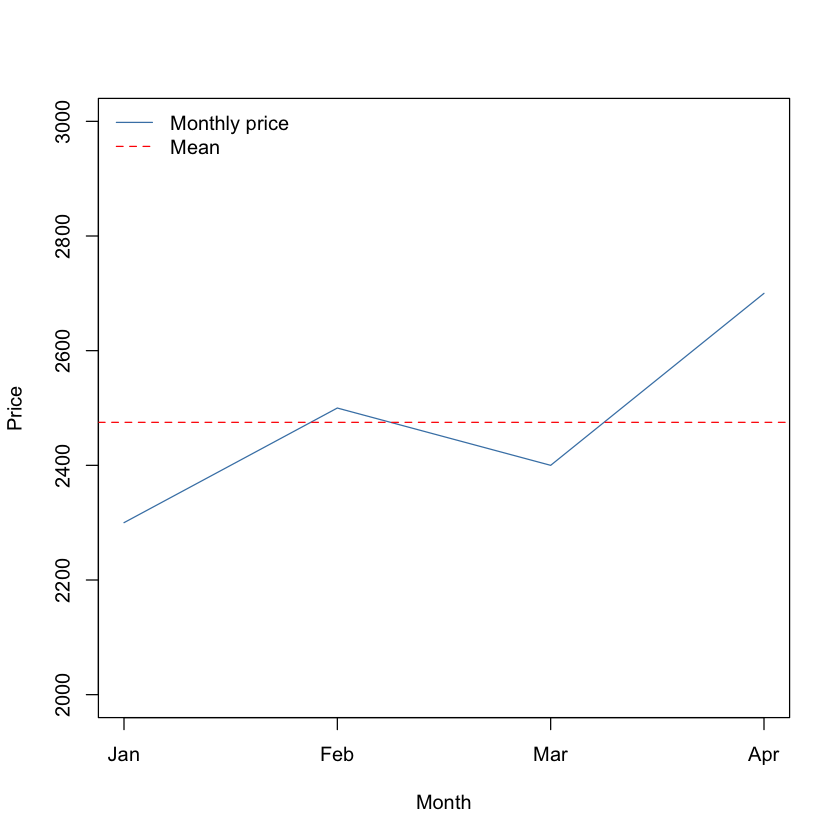

In [6]:
months <- 1:4
price <- c(2300, 2500, 2400, 2700)
plot(months, price, type = "l", xaxt = "n", col = "steelblue",
     ylim = c(2000, 3000), xlab = "Month", ylab = "Price")
axis(1, at = months, labels = c("Jan", "Feb", "Mar", "Apr"))
abline(h = mean(price), col = "red", lty = 2)
legend("topleft", legend = c("Monthly price", "Mean"),
       col = c("steelblue", "red"), lty = c(1, 2), bty = "n")

## 我的练习 / My practice
在下面自由编写 R 代码。

In [7]:
# 在这里写 R 代码
